## Phase 2 EDA by Jenitha P

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional look
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load data (assuming your Phase 1 code has already run)
sub = pd.read_csv("D:/Internship/Streamflix/subscribers.csv")
titles = pd.read_csv("D:/Internship/Streamflix/titles.csv")
wh = pd.read_csv("D:/Internship/Streamflix/watch_history.csv")
wl = pd.read_csv("D:/Internship/Streamflix/watchlist.csv")
rev = pd.read_csv("D:/Internship/Streamflix/reviews.csv")
rate = pd.read_csv("D:/Internship/Streamflix/ratings.csv")

# Ensure dates are parsed properly
wh['watch_date'] = pd.to_datetime(wh['watch_date'])
sub['signup_date'] = pd.to_datetime(sub['signup_date'])

# Extract Month-Year periods for time-series charts
wh['watch_month'] = wh['watch_date'].dt.to_period('M').astype(str)

# Pre-merge watch history with titles for genre/type tracking
wh_titles = wh.merge(titles[['title_id', 'primary_genre', 'type']], on='title_id', how='left')


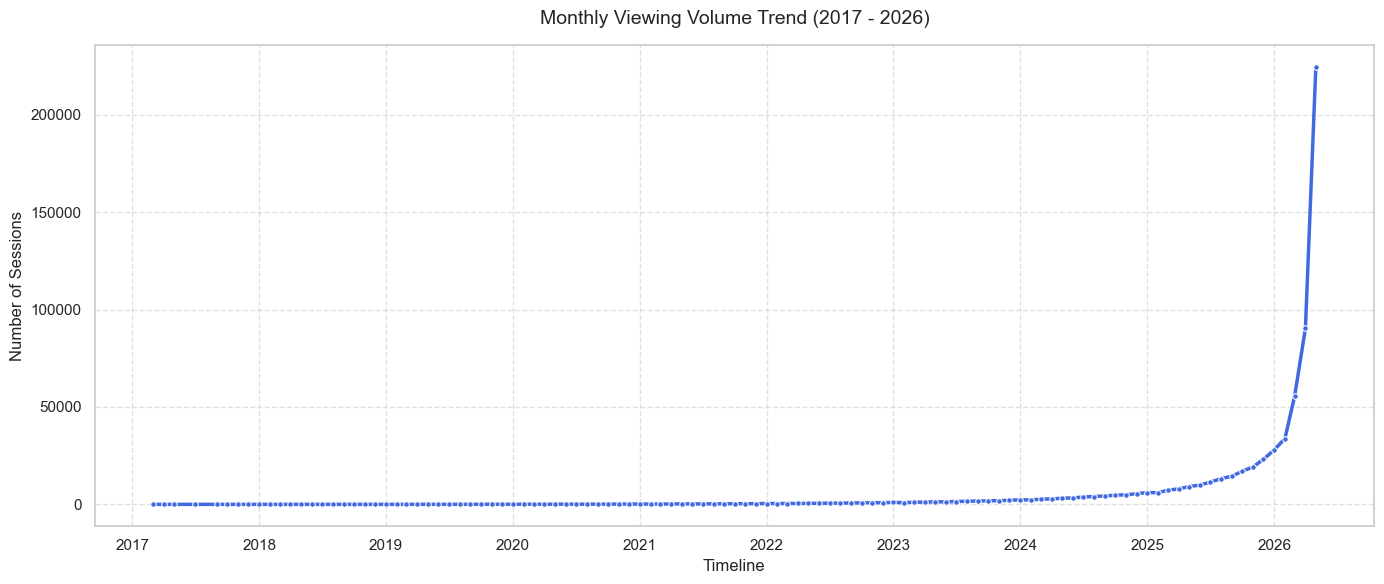

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure dates are datetime objects and group chronologically
wh['watch_date'] = pd.to_datetime(wh['watch_date'])
volume_trend = wh['watch_date'].dt.to_period('M').value_counts().sort_index()

# Convert PeriodIndex to a true timestamp for flawless chronological line plotting
x_dates = volume_trend.index.to_timestamp()

plt.figure(figsize=(14, 6))

# A line plot perfectly handles a 114-month continuous timeline without crowding
sns.lineplot(x=x_dates, y=volume_trend.values, color='royalblue', linewidth=2.5, marker='o', markersize=4)

plt.title('Monthly Viewing Volume Trend (2017 - 2026)', fontsize=14, pad=15)
plt.xlabel('Timeline', fontsize=12)
plt.ylabel('Number of Sessions', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('1_monthly_viewing_volume.png')
plt.show()


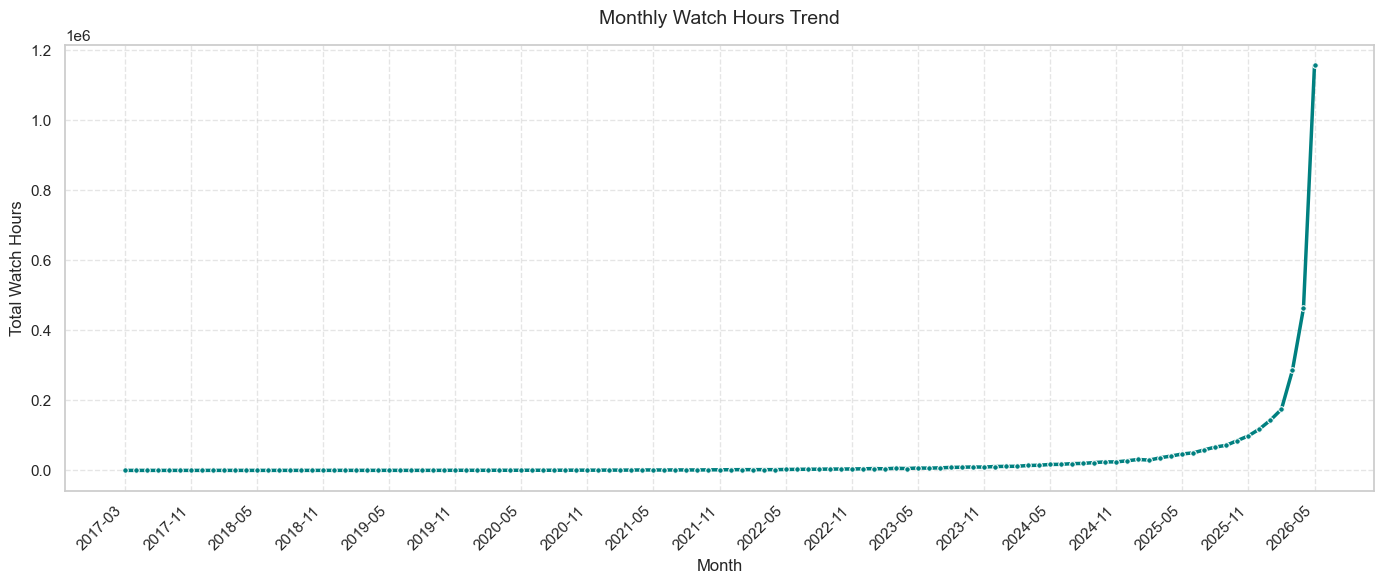

In [22]:
# Convert minutes to hours properly
wh['watch_hours'] = wh['watch_duration_min'] / 60

# Group watch hours by chronological periods to prevent chronological timeline jumps
hours_trend = wh.groupby(wh['watch_date'].dt.to_period('M'))['watch_hours'].sum().sort_index()

x_labels_hours = hours_trend.index.astype(str)

plt.figure(figsize=(14, 6))
sns.lineplot(x=x_labels_hours, y=hours_trend.values, color='teal', linewidth=2.5, marker='o', markersize=4)

plt.title('Monthly Watch Hours Trend', fontsize=14, pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Watch Hours', fontsize=12)

# Ensure matching X-axis label breaks for symmetry
plt.xticks(ticks=range(0, len(x_labels_hours), 6), labels=x_labels_hours[::6], rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('2_monthly_watch_hours.png')
plt.show()


C:\Users\manok\AppData\Local\Temp\ipykernel_15792\4244204583.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_hours.values, y=genre_hours.index, palette='viridis')


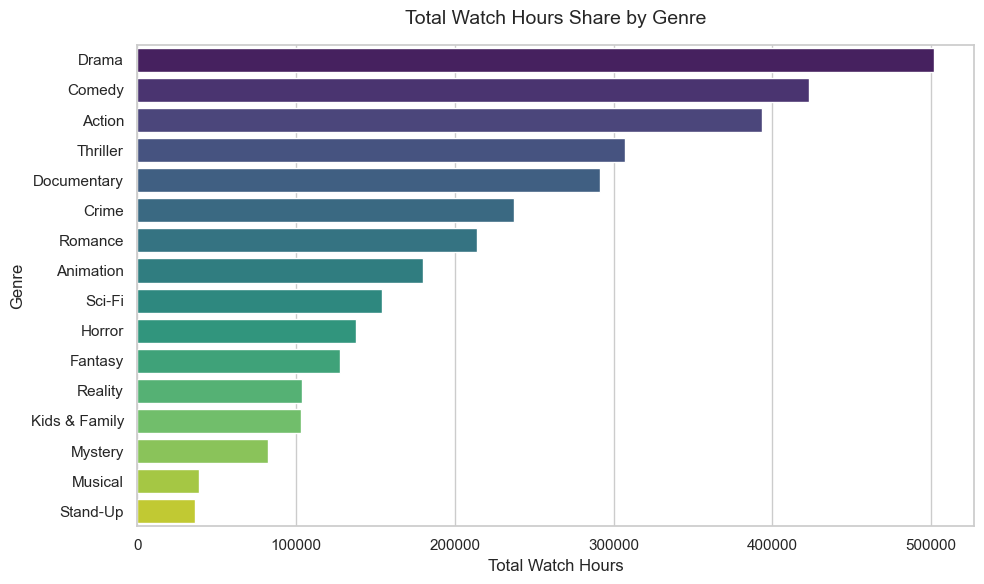

In [9]:
wh_titles['watch_hours'] = wh_titles['watch_duration_min'] / 60
genre_hours = wh_titles.groupby('primary_genre')['watch_hours'].sum().sort_values(ascending=False)

plt.figure()
sns.barplot(x=genre_hours.values, y=genre_hours.index, palette='viridis')
plt.title('Total Watch Hours Share by Genre', fontsize=14, pad=15)
plt.xlabel('Total Watch Hours')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('3_genre_watch_hours.png')
plt.show()


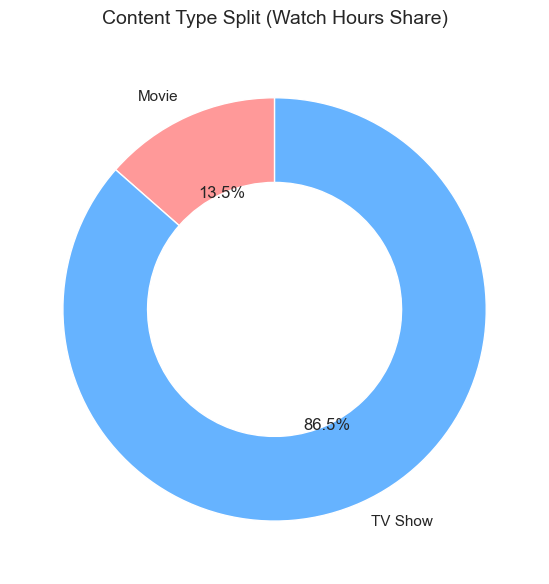

In [10]:
type_hours = wh_titles.groupby('type')['watch_hours'].sum()

plt.figure()
plt.pie(type_hours, labels=type_hours.index, autopct='%1.1f%%', startangle=90, 
        colors=['#ff9999','#66b3ff'], wedgeprops=dict(width=0.4, edgecolor='w'))
plt.title('Content Type Split (Watch Hours Share)', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('4_content_type_split.png')
plt.show()


C:\Users\manok\AppData\Local\Temp\ipykernel_15792\1376970704.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_hours.values, y=country_hours.index, palette='magma')


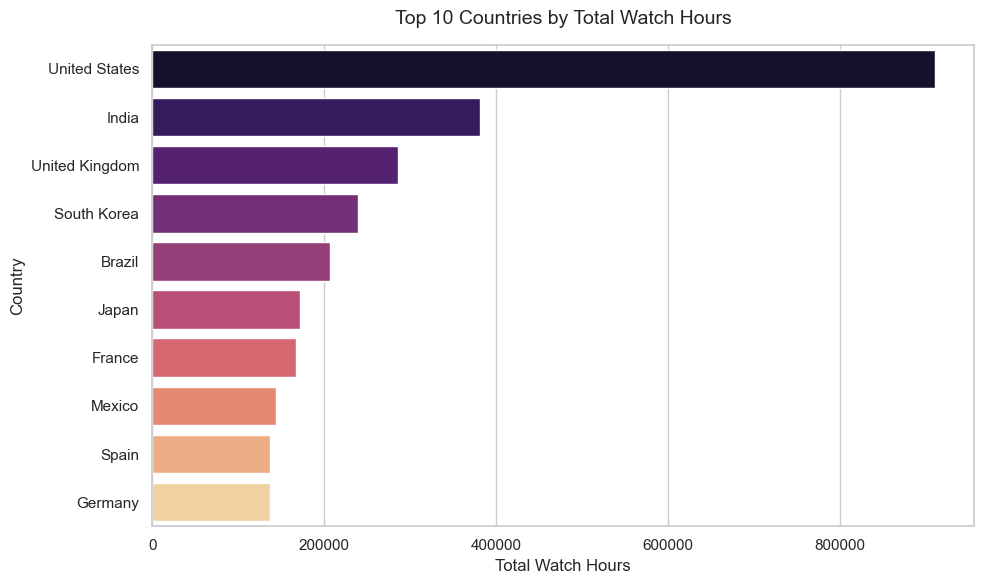

In [11]:
# Merge watch history with subscriber profiles to pull geography details
wh_subs = wh.merge(sub[['subscriber_id', 'country']], on='subscriber_id', how='left')
wh_subs['watch_hours'] = wh_subs['watch_duration_min'] / 60
country_hours = wh_subs.groupby('country')['watch_hours'].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=country_hours.values, y=country_hours.index, palette='magma')
plt.title('Top 10 Countries by Total Watch Hours', fontsize=14, pad=15)
plt.xlabel('Total Watch Hours')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('5_top_10_countries.png')
plt.show()


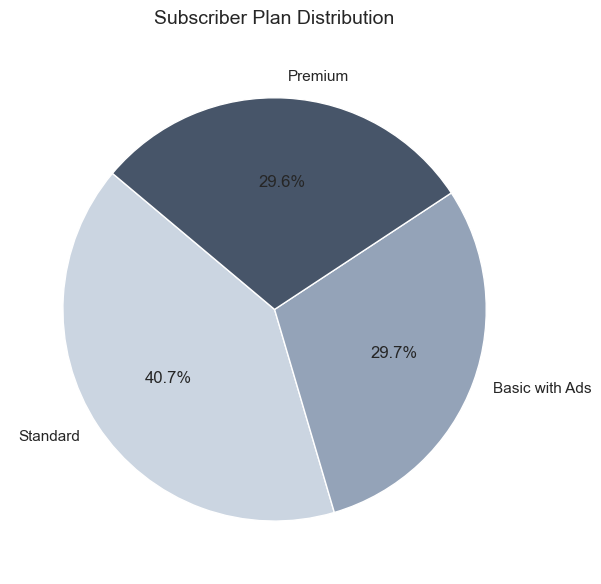

In [12]:
plan_counts = sub['plan_type'].value_counts()

plt.figure()
plt.pie(plan_counts, labels=plan_counts.index, autopct='%1.1f%%', startangle=140, 
        colors=['#cbd5e1', '#94a3b8', '#475569'])
plt.title('Subscriber Plan Distribution', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('6_subscriber_plans.png')
plt.show()


C:\Users\manok\AppData\Local\Temp\ipykernel_15792\1802159806.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=device_counts.index, y=device_counts.values, palette='muted')


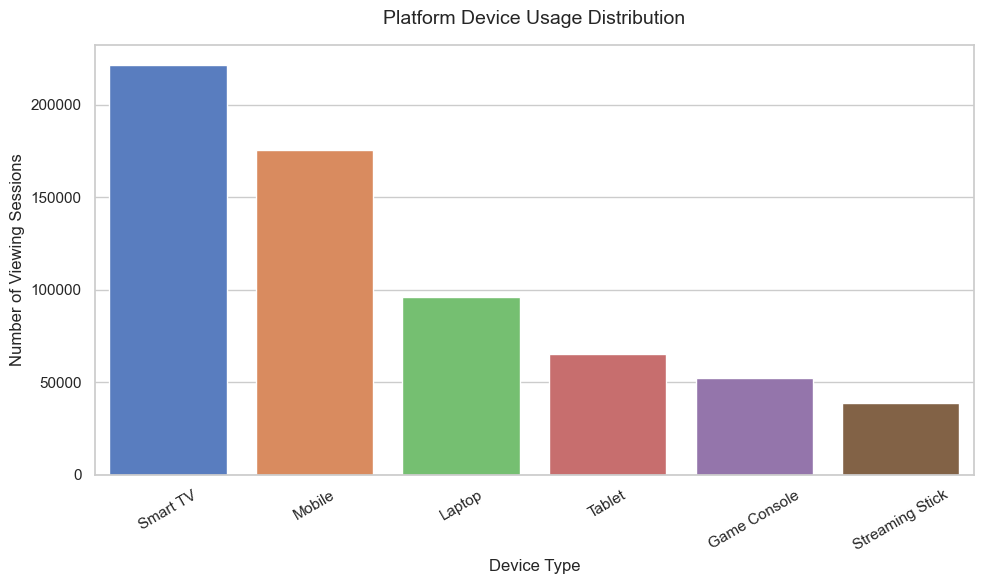

In [13]:
device_counts = wh['device'].value_counts()

plt.figure()
sns.barplot(x=device_counts.index, y=device_counts.values, palette='muted')
plt.title('Platform Device Usage Distribution', fontsize=14, pad=15)
plt.xlabel('Device Type')
plt.ylabel('Number of Viewing Sessions')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('7_device_usage.png')
plt.show()


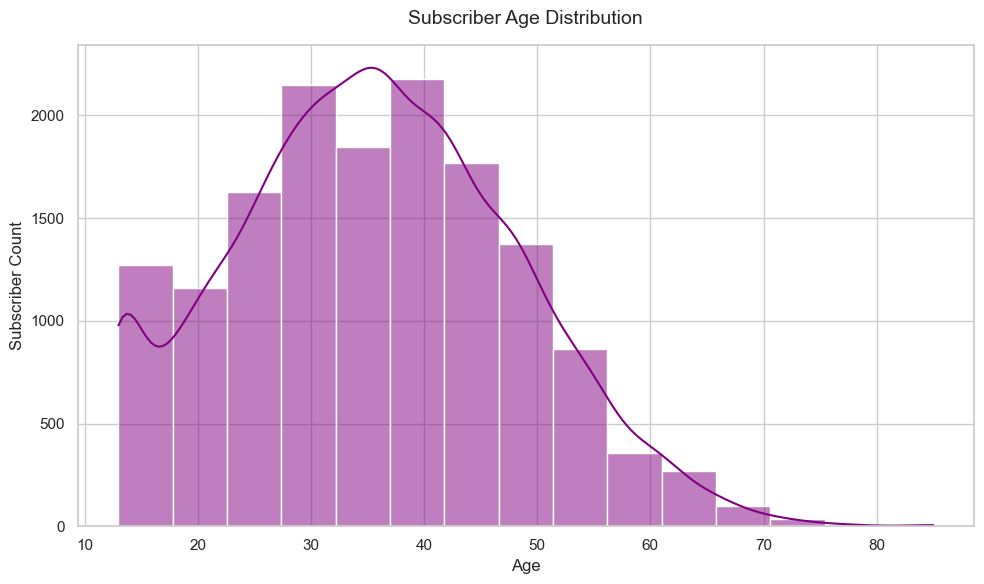

In [14]:
plt.figure()
sns.histplot(sub['age'], bins=15, kde=True, color='purple')
plt.title('Subscriber Age Distribution', fontsize=14, pad=15)
plt.xlabel('Age')
plt.ylabel('Subscriber Count')
plt.tight_layout()
plt.savefig('8_age_distribution.png')
plt.show()


C:\Users\manok\AppData\Local\Temp\ipykernel_15792\3307111827.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_completion.values, y=genre_completion.index, palette='coolwarm')


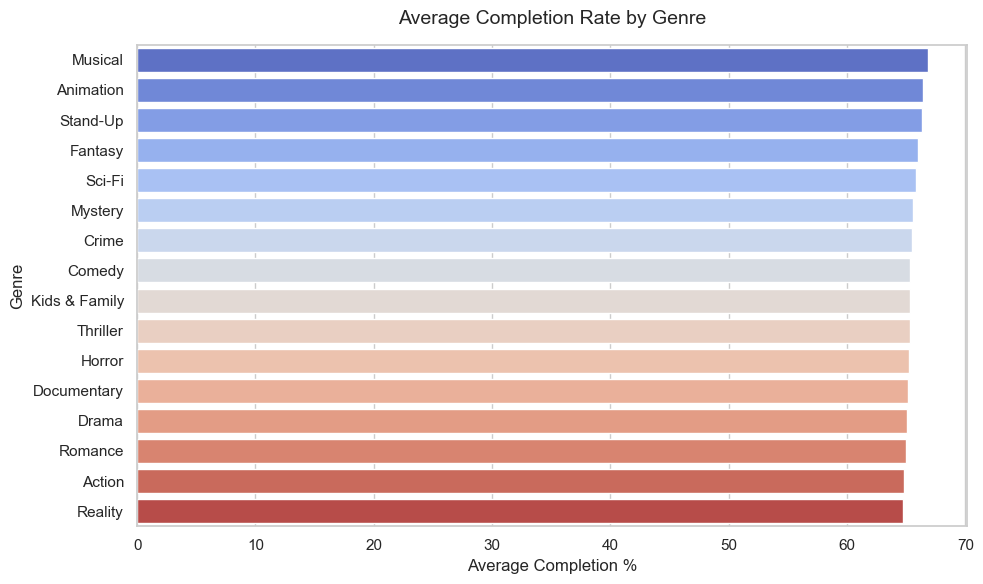

In [15]:
genre_completion = wh_titles.groupby('primary_genre')['completion_pct'].mean().sort_values(ascending=False)

plt.figure()
sns.barplot(x=genre_completion.values, y=genre_completion.index, palette='coolwarm')
plt.title('Average Completion Rate by Genre', fontsize=14, pad=15)
plt.xlabel('Average Completion %')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('9_genre_completion_rate.png')
plt.show()


C:\Users\manok\AppData\Local\Temp\ipykernel_15792\1480677639.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette=['#4ade80', '#94a3b8', '#f87171'])


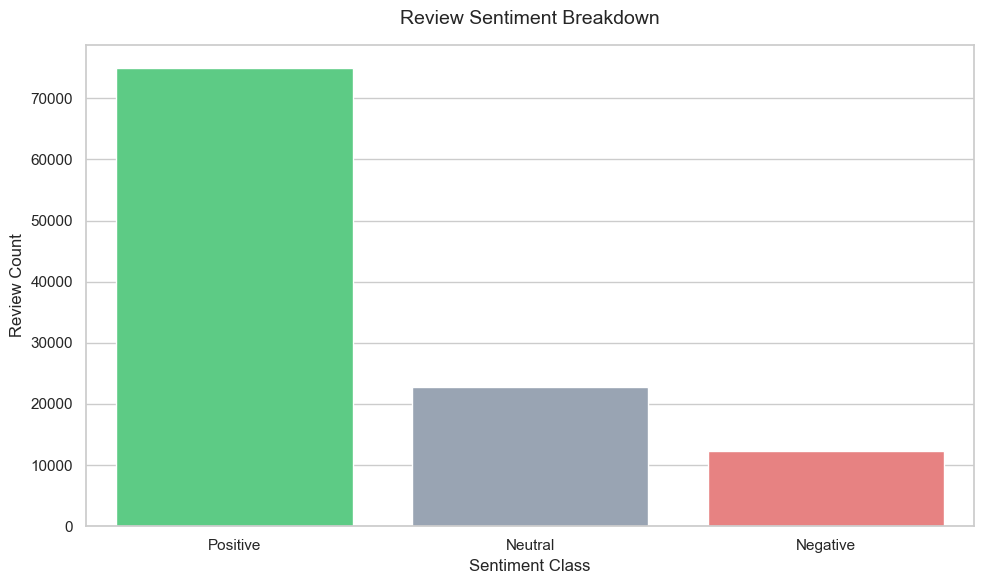

In [16]:
sentiment_counts = rev['sentiment'].value_counts()

plt.figure()
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, palette=['#4ade80', '#94a3b8', '#f87171'])
plt.title('Review Sentiment Breakdown', fontsize=14, pad=15)
plt.xlabel('Sentiment Class')
plt.ylabel('Review Count')
plt.tight_layout()
plt.savefig('10_sentiment_breakdown.png')
plt.show()
